# E4 — Interprétabilité Grad-CAM (validation, seuil COVID 0,35)

**Objectif :** expliquer visuellement les prédictions du checkpoint **E4 VGG16 fine-tuné**, sur quelques images de **validation** (TP, FN, FP et TN). Aucun réentraînement et **aucun accès au test**.

**Référence pédagogique :** cours DataScientest/Liora `151.2.5_Interpretability_CNN`, partie Grad-CAM : (1) gradients, (2) poids par canal, (3) carte de chaleur, (4) superposition.

**Spécificités E4 :** VGG16 est imbriqué dans un modèle `Sequential` ; la sortie est **sigmoïde binaire** (P(COVID)), donc on ne fait **pas** `argmax` sur la sortie comme dans l'exemple multiclasses du cours. Le **seuil 0,35** sert à classer les exemples, mais **ne modifie pas** Grad-CAM.

**Avant d'exécuter :** monter Drive ; si nouveau runtime Colab, décommenter la copie des images vers `/content/` (elle peut prendre plusieurs minutes).

In [1]:
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
import shutil, time, json, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.models import load_model
from sklearn.metrics import confusion_matrix

PROJECT_DIR = Path('/content/drive/MyDrive/Apprentissage/DS/projet')
DATASET_ROOT = Path('/content/COVID-19_Radiography_Dataset')
DRIVE_DATASET_ROOT = PROJECT_DIR / 'COVID-19_Radiography_Dataset'
CHECKPOINT = PROJECT_DIR / 'E4_finetuning' / 'E4_FT_B5_LR1e-5_best.keras'
OUTPUT_DIR = PROJECT_DIR / 'E4_interpretabilite_GradCAM'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
THRESHOLD = 0.35
SEED = 42

# Si nouveau runtime Colab, décommenter :
if not DATASET_ROOT.exists():
     start = time.perf_counter()
     shutil.copytree(DRIVE_DATASET_ROOT, DATASET_ROOT)
     print('Copie locale :', round((time.perf_counter()-start)/60, 1), 'min')

assert DATASET_ROOT.is_dir(), 'Images locales absentes : décommenter la copie.'
assert CHECKPOINT.is_file(), f'Checkpoint absent : {CHECKPOINT}'
print('GPU :', tf.config.list_physical_devices('GPU'))
print('Checkpoint :', CHECKPOINT)

Mounted at /content/drive
Copie locale : 18.2 min
GPU : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Checkpoint : /content/drive/MyDrive/Apprentissage/DS/projet/E4_finetuning/E4_FT_B5_LR1e-5_best.keras


## 1. Validation : mêmes images, même ordre et même prétraitement que pour les seuils

La colonne `target=1` doit correspondre à COVID. Le CSV contient des chemins Windows qu'on reconstruit vers `/content/`.

In [2]:
val_df = pd.read_csv(PROJECT_DIR / 'validation.csv')
def local_filepath(original):
    normalized = str(original).replace('\\', '/')
    marker = 'COVID-19_Radiography_Dataset/'
    if marker not in normalized:
        raise ValueError(f'Chemin inattendu : {original}')
    return str(DATASET_ROOT / normalized.split(marker, 1)[1])

val_df['filepath'] = val_df['filepath'].map(local_filepath)
val_df['target'] = val_df['target'].astype(int)
assert len(val_df) == 3387
assert set(val_df['target'].unique()) == {0, 1}
assert int(val_df['target'].sum()) == 579, 'Vérifier mapping COVID=1.'
assert val_df['filepath'].map(lambda p: Path(p).is_file()).all()

generator = ImageDataGenerator(preprocessing_function=preprocess_input).flow_from_dataframe(
    val_df.assign(target=val_df['target'].astype(str)),
    x_col='filepath', y_col='target', classes=['0','1'],
    target_size=(224,224), color_mode='rgb',
    class_mode='binary', batch_size=32, shuffle=False
)
assert generator.class_indices == {'0': 0, '1': 1}
print('Images validation :', len(val_df), 'dont COVID :', val_df['target'].sum())

Found 3387 validated image filenames belonging to 2 classes.
Images validation : 3387 dont COVID : 579


## 2. Charger le checkpoint E4 (sans l'entraîner)

Un correctif de compatibilité Keras est prévu uniquement si l'erreur connue `GlorotUniform / input_axes` apparaît. La copie corrigée est créée dans `/content/`, sans modifier le checkpoint Drive.

In [3]:
def load_compatible_checkpoint(path):
    try:
        return load_model(path, compile=False)
    except (TypeError, ValueError) as exc:
        if 'input_axes' not in str(exc) and 'output_axes' not in str(exc):
            raise
        print('Correctif de compatibilité GlorotUniform…')
        compat = Path('/content/E4_gradcam_compatible.keras')
        def clean(obj):
            if isinstance(obj, dict):
                if obj.get('class_name') == 'GlorotUniform':
                    obj.get('config', {}).pop('input_axes', None)
                    obj.get('config', {}).pop('output_axes', None)
                for v in obj.values(): clean(v)
            elif isinstance(obj, list):
                for v in obj: clean(v)
        with zipfile.ZipFile(path) as src:
            config = json.loads(src.read('config.json'))
            clean(config)
            with zipfile.ZipFile(compat, 'w') as dst:
                for member in src.infolist():
                    payload = json.dumps(config).encode() if member.filename == 'config.json' else src.read(member.filename)
                    dst.writestr(member, payload)
        return load_model(compat, compile=False)

model = load_compatible_checkpoint(CHECKPOINT)
model.summary()
assert len(model.output_shape) == 2 and model.output_shape[-1] == 1, 'Sortie E4 attendue : sigmoid (batch,1).'
generator.reset()
prob = np.asarray(model.predict(generator, verbose=1)).reshape(-1)
true = np.asarray(generator.classes, dtype=int)  # classes est parfois une liste Python
assert len(prob) == len(true) == len(val_df)
assert np.isfinite(prob).all() and ((prob >= 0) & (prob <= 1)).all()
pred = (prob >= THRESHOLD).astype(int)
tn, fp, fn, tp = confusion_matrix(true, pred, labels=[0,1]).ravel()
print(f'Seuil {THRESHOLD:.2f} : TP={tp}, FN={fn}, FP={fp}, TN={tn}')
print('Attendu pour checkpoint et validation déjà évalués : TP=561, FN=18, FP=16.')
if (tp,fn,fp)!=(561,18,16):
    print('ATTENTION : chiffres différents ; vérifier checkpoint, ordre des images et mapping avant interprétation.')

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,780,481 (56.38 MB)

 Trainable params: 7,145,217 (27.26 MB)

 Non-trainable params: 7,635,264 (29.13 MB)

106/106 ━━━━━━━━━━━━━━━━━━━━ 24s 182ms/step
Seuil 0.35 : TP=561, FN=18, FP=16, TN=2792
Attendu pour checkpoint et validation déjà évalués : TP=561, FN=18, FP=16.


## 3. Choisir des exemples représentatifs

On choisit automatiquement **jusqu'à 3 TP, 3 FN, 3 FP et 2 TN**, avec une sélection reproductible. On évite de choisir uniquement les images dont les cartes sont visuellement flatteuses.

- **TP** : COVID correctement détecté.
- **FN** : COVID manqué (particulièrement important).
- **FP** : non-COVID classé COVID.
- **TN** : non-COVID correctement rejeté.

Pour les négatifs, on expliquera **le score COVID** (ce qui pousse ou aurait poussé vers COVID), et non une classe « non-COVID » artificielle.

In [4]:
case_groups = {
    'TP': np.where((true == 1) & (pred == 1))[0],
    'FN': np.where((true == 1) & (pred == 0))[0],
    'FP': np.where((true == 0) & (pred == 1))[0],
    'TN': np.where((true == 0) & (pred == 0))[0],
}
rng = np.random.default_rng(SEED)
selection = []
for group, n in [('TP',3), ('FN',3), ('FP',3), ('TN',2)]:
    pool = case_groups[group]
    picked = rng.choice(pool, size=min(n,len(pool)), replace=False)
    selection.extend([(group,int(i)) for i in picked])
print('Exemples retenus :', {g: sum(k==g for k,_ in selection) for g in case_groups})

Exemples retenus : {'TP': 3, 'FN': 3, 'FP': 3, 'TN': 2}


## 4. Construire Grad-CAM adapté au VGG16 imbriqué

Le cours Liora propose de créer un modèle donnant **activations convolutives + prédiction**, puis de calculer les gradients avec `tf.GradientTape`, leur moyenne spatiale et une carte pondérée.

Ici VGG16 est un **sous-modèle** : on construit un extracteur renvoyant `block5_conv3` et les features VGG16, puis on applique la tête de classification d'E4. On vérifie numériquement que ce chemin donne **les mêmes probabilités** que `model` avant de calculer une seule carte. Cela évite les erreurs de graphe Keras avec les modèles imbriqués.

In [5]:
# E4 fine-tuning : VGG16 est le premier élément du Sequential.
base = next((layer for layer in model.layers if isinstance(layer, tf.keras.Model)
             and any(l.name == 'block5_conv3' for l in layer.layers)), None)
assert base is not None, 'VGG16 imbriqué non trouvé : inspecter model.summary().'
last_conv = base.get_layer('block5_conv3')
conv_extractor = tf.keras.Model(
    inputs=base.inputs,
    outputs=[last_conv.output, base.output],
    name='vgg16_features_et_block5conv3'
)
base_index = model.layers.index(base)
head_layers = [layer for layer in model.layers[base_index+1:]
               if not isinstance(layer, tf.keras.layers.InputLayer)]
print('Couche Grad-CAM :', last_conv.name)
print('Tête E4 :', [l.name for l in head_layers])

def gradcam_forward(x):
    activations, features = conv_extractor(x, training=False)
    z = features
    for layer in head_layers:
        z = layer(z, training=False)
    return activations, z

# Vérification critique : le chemin utilisé pour les gradients doit reproduire le modèle.
sample_x, _ = generator[0]
sample_x = tf.convert_to_tensor(sample_x[:2], dtype=tf.float32)
_, reconstructed = gradcam_forward(sample_x)
original = model(sample_x, training=False)
max_diff = float(tf.reduce_max(tf.abs(reconstructed - original)).numpy())
print('Différence maximale de probabilité (doit être ~0) :', max_diff)
assert max_diff < 1e-4, 'Graphe Grad-CAM incohérent avec E4. Ne pas interpréter les cartes.'

def make_gradcam(preprocessed_image):
    x = tf.convert_to_tensor(preprocessed_image[None,...], dtype=tf.float32)
    with tf.GradientTape() as tape:
        conv_outputs, scores = gradcam_forward(x)
        covid_score = scores[:,0]  # sigmoid : probabilité de COVID
    grads = tape.gradient(covid_score, conv_outputs)
    if grads is None:
        raise RuntimeError('Gradients absents : vérifier le graphe VGG16 / tête.')
    weights = tf.reduce_mean(grads, axis=(0,1,2))
    heatmap = tf.reduce_sum(conv_outputs[0] * weights, axis=-1)
    heatmap = tf.nn.relu(heatmap)
    heatmap = heatmap / (tf.reduce_max(heatmap) + tf.keras.backend.epsilon())
    return heatmap.numpy()

Couche Grad-CAM : block5_conv3
Tête E4 : ['global_average_pooling2d', 'dense', 'dropout', 'dense_1']
Différence maximale de probabilité (doit être ~0) : 0.0


## 5. Superposer les cartes et enregistrer les figures

La carte est calculée sur les images **prétraitées comme à l'entraînement** (`preprocess_input` VGG16), mais superposée à la radiographie **non prétraitée** pour rester lisible. Le dossier Drive conserve les figures et le CSV des cas.

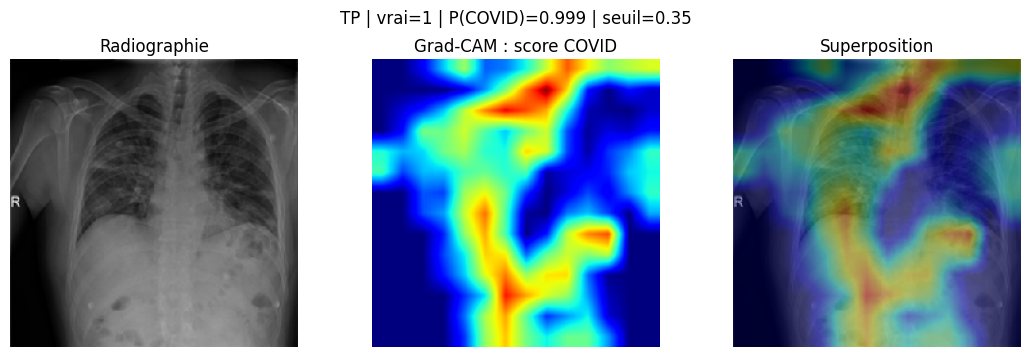

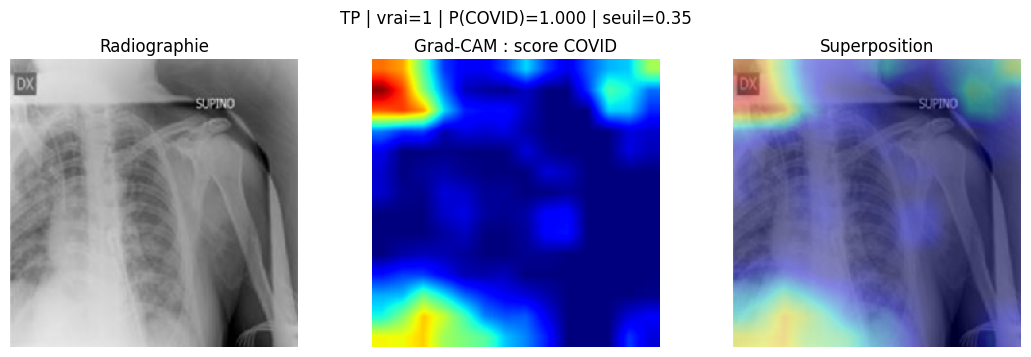

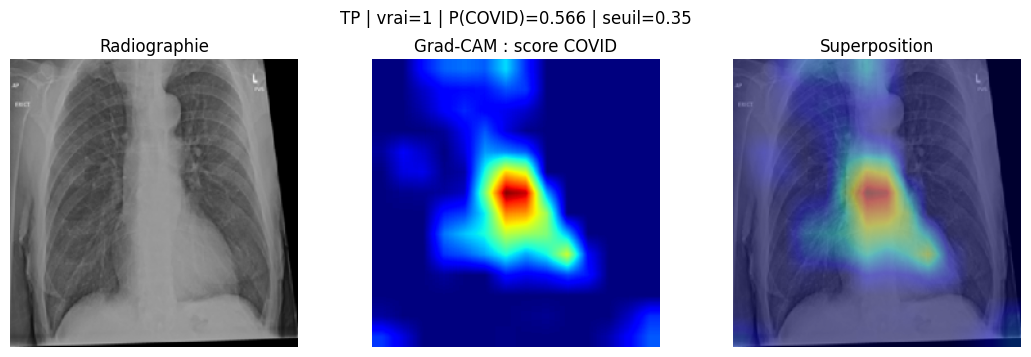

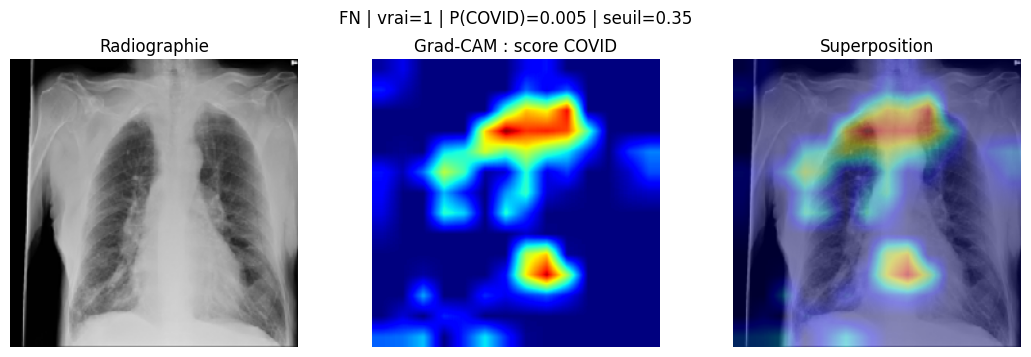

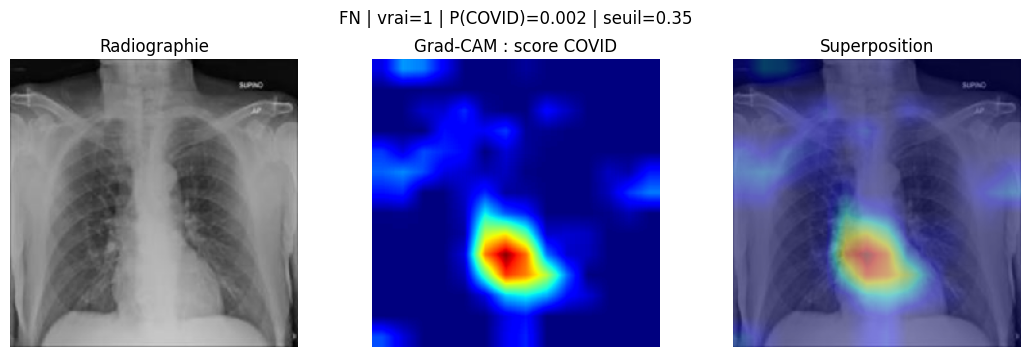

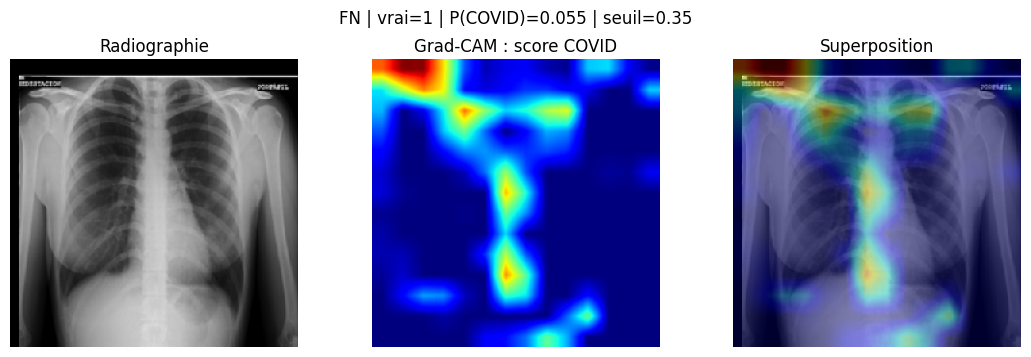

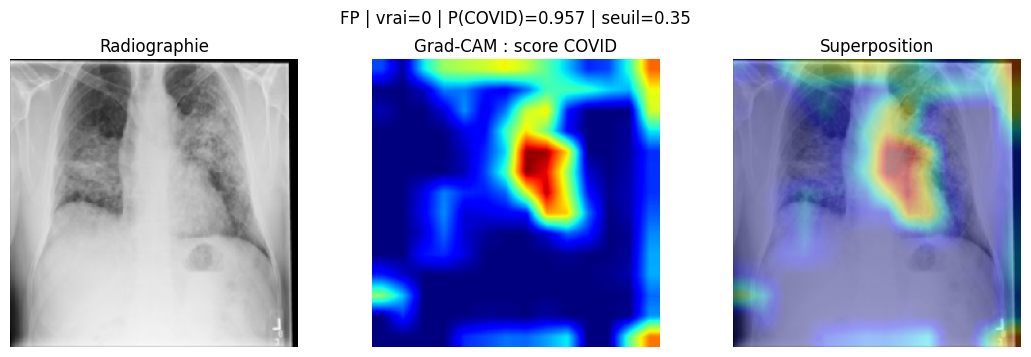

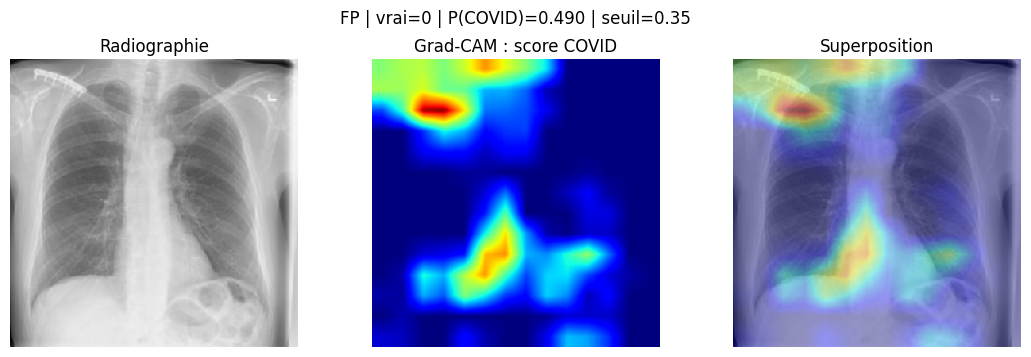

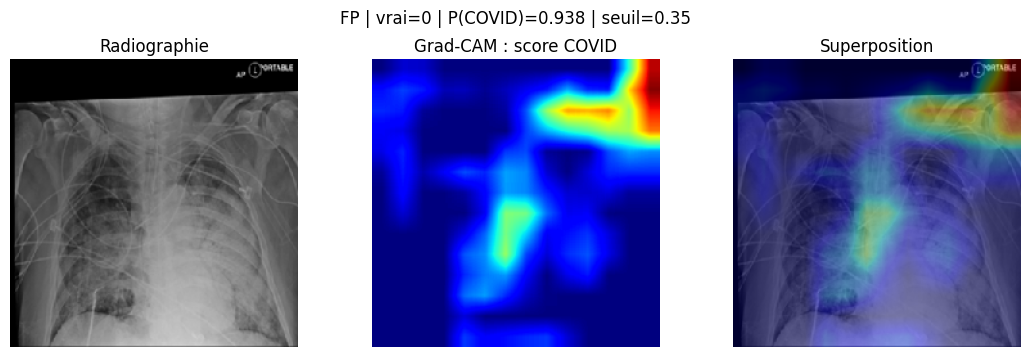

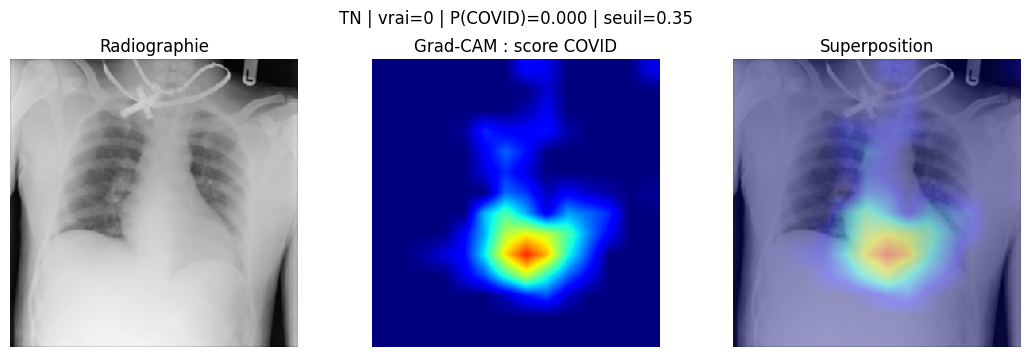

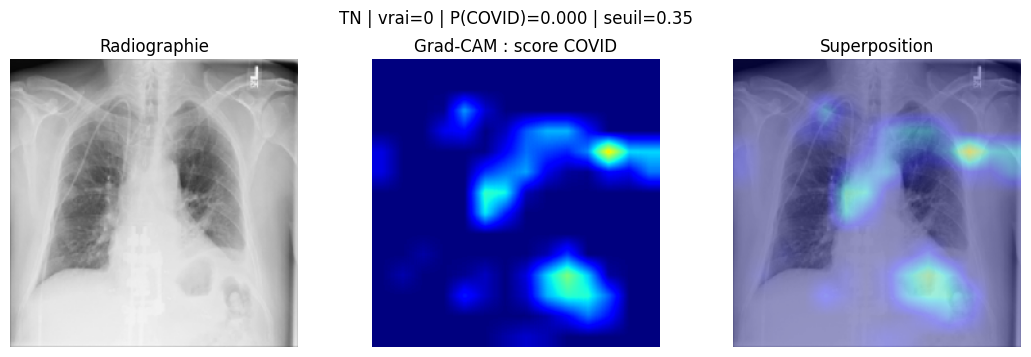

Figures et CSV enregistrés dans : /content/drive/MyDrive/Apprentissage/DS/projet/E4_interpretabilite_GradCAM


In [6]:
from PIL import Image

def load_for_gradcam(filepath):
    pil = load_img(filepath, target_size=(224,224), color_mode='rgb')
    rgb = img_to_array(pil).astype('uint8')
    preprocessed = preprocess_input(rgb.astype('float32').copy())
    return rgb, preprocessed

rows = []
for group, idx in selection:
    row = val_df.iloc[idx]
    rgb, x = load_for_gradcam(row['filepath'])
    heatmap = make_gradcam(x)
    heatmap_resized = np.asarray(Image.fromarray(np.uint8(255*heatmap)).resize(
        (224,224), resample=Image.Resampling.BILINEAR)) / 255.
    fig, axes = plt.subplots(1,3,figsize=(11,3.6))
    axes[0].imshow(rgb); axes[0].set_title('Radiographie')
    axes[1].imshow(heatmap_resized,cmap='jet',vmin=0,vmax=1); axes[1].set_title('Grad-CAM : score COVID')
    axes[2].imshow(rgb); axes[2].imshow(heatmap_resized,cmap='jet',alpha=.38,vmin=0,vmax=1)
    axes[2].set_title('Superposition')
    for ax in axes: ax.axis('off')
    fig.suptitle(f'{group} | vrai={true[idx]} | P(COVID)={prob[idx]:.3f} | seuil={THRESHOLD:.2f}')
    fig.tight_layout()
    filename = f'E4_GradCAM_{group}_index{idx:04d}.png'
    fig.savefig(OUTPUT_DIR / filename, dpi=170, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    rows.append(dict(groupe=group,index_validation=idx,filepath=row['filepath'],
                     vrai=int(true[idx]),prediction=int(pred[idx]),
                     proba_COVID=float(prob[idx]),seuil=THRESHOLD,figure=filename))
pd.DataFrame(rows).to_csv(OUTPUT_DIR/'E4_GradCAM_selection_validation.csv',index=False)
print('Figures et CSV enregistrés dans :', OUTPUT_DIR)

## 6. Interpréter les cartes (à compléter après exécution)

Pour chaque figure, se demander :

1. Les zones chaudes sont-elles principalement dans les **champs pulmonaires** ou sur des éléments périphériques (bord, annotations, fond) ?
2. Les TP présentent-ils des régions cohérentes entre eux ? Les FN ou FP attirent-ils l'attention sur d'autres zones ?
3. La carte est-elle diffuse ou très localisée ? **Une zone chaude n'est pas une lésion identifiée.**
4. Le modèle peut-il exploiter des **artefacts de source** (cadrage, texte, contraste, appareil) ?

**Limites importantes :** Grad-CAM est une visualisation de sensibilité approximative, pas une validation clinique, ni une preuve de causalité. La résolution spatiale du dernier bloc convolutif est faible ; l'interpolation agrandit une carte grossière. L'analyse porte sur un échantillon choisi sur validation, pas sur le test.

**Pour le rapport :** présenter la méthode, quelques TP/FN/FP, les observations réellement constatées et ces limites. Ne pas affirmer que le modèle « regarde les lésions COVID » sans expertise médicale.

**Suite :** lorsque le modèle et le seuil seront définitivement figés, évaluer une seule fois sur le jeu de test. Ne pas utiliser le test pour ajuster Grad-CAM ou le seuil.